## YoloV8_based_PPE_Complaince_Detection_System

#####  To count the dataset images and labels

In [1]:
from pathlib import Path

root = Path(r"C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset")

for s in ["train","test","valid"]:
    img = list((root/s/"images").glob("*.*"))
    lbs = list((root/s/"labels").glob("*.txt"))

    #print(f"images:",len(img))
    #print(f"labels:",len(lbs))

    print(f"{s}: images = {len(img)}, labels ={len(lbs)}")

print(open(root/"data.yaml").read())

train: images = 3248, labels =3248
test: images = 406, labels =406
valid: images = 406, labels =406
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['helmet', 'no_helmet', 'no_vest', 'person', 'vest']



##### To Count the classes:


In [2]:
import yaml
from collections import Counter

names = yaml.safe_load(open(root / "data.yaml"))["names"]
for split in ["train", "valid", "test"]:
    c = Counter()
    for f in (root / split / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                c[names[int(line.split()[0])]] += 1
    print(split, dict(c))

train {'helmet': 4068, 'no_vest': 4912, 'person': 8259, 'no_helmet': 3993, 'vest': 2952}
valid {'helmet': 531, 'person': 1042, 'no_vest': 649, 'vest': 350, 'no_helmet': 523}
test {'helmet': 529, 'vest': 396, 'person': 954, 'no_vest': 513, 'no_helmet': 393}


##### Image and box sizes

In [3]:
from PIL import Image
import numpy as np

sizes = Counter()
for img in (root / "train" / "images").glob("*.*"):
    sizes[Image.open(img).size] += 1
print(sizes.most_common(5))

areas = {n: [] for n in names}
for f in (root / "train" / "labels").glob("*.txt"):
    for line in f.read_text().splitlines():
        if line.strip():
            c, x, y, w, h = line.split()[:5]
            areas[names[int(c)]].append(float(w) * float(h))
for n, a in areas.items():
    print(n, "median box area (% of image):", round(np.median(a) * 100, 2))

[((640, 640), 3248)]
helmet median box area (% of image): 0.48
no_helmet median box area (% of image): 0.31
no_vest median box area (% of image): 1.09
person median box area (% of image): 5.76
vest median box area (% of image): 4.43


##### Dataset validations:

In [4]:
bad_imgs, bad_labels, empty = [], [], 0
for split in ["train", "valid", "test"]:
    for img in (root / split / "images").glob("*.*"):
        try:
            Image.open(img).verify()
        except Exception:
            bad_imgs.append(img.name)
    for f in (root / split / "labels").glob("*.txt"):
        lines = [l for l in f.read_text().splitlines() if l.strip()]
        if not lines:
            empty += 1
        for l in lines:
            p = l.split()
            c, x, y, w, h = int(p[0]), *map(float, p[1:5])
            if len(p) < 5 or c > 4 or not all(0 <= v <= 1 for v in (x, y, w, h)) or w == 0 or h == 0:
                bad_labels.append((split, f.name))

print("corrupt images:", len(bad_imgs))
print("bad label lines:", len(bad_labels))
print("empty label files:", empty)

corrupt images: 0
bad label lines: 0
empty label files: 0


In [5]:
import torch
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu128 True


##### Smoke test the yolo model with one epochs:

In [6]:
from ultralytics import YOLO

aug = dict(fliplr=0.5,degrees=10,hsv_v=0.4,hsv_s=0.5,scale=0.5)

model = YOLO("yolov8n.pt")
model.train(
    data=r"C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\data.yaml",
    epochs=1,
    batch=10,
    imgsz=640,
    device=0,
    workers=2,
    project=str(root.parent/"runs"),
    name="yolov8nsmoketest",
    **aug

)

Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, n

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001A249296150>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
    

##### Validate:

In [7]:
metrics = model.val(data=str(root / "data.yaml"), device=0)
for i, n in enumerate(model.names.values()):
    print(f"{n:10s} P={metrics.box.p[i]:.3f} R={metrics.box.r[i]:.3f} mAP50={metrics.box.ap50[i]:.3f} mAP50-95={metrics.box.ap[i]:.3f}")

Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 578.6±235.7 MB/s, size: 53.4 KB)
val: Scanning C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\valid\labels.cache... 406 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 406/406  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 1.2it/s 22.0s0.2s
                   all        406       3095      0.577      0.544      0.555      0.222
                helmet        246        531      0.717      0.593      0.671      0.296
             no_helmet        241        523      0.613      0.386      0.457      0.166
               no_vest        269        649      0.492      0.538      0.496       0.19
                person        406       1042      0.655       0.67      0.6

##### train YOLOv8n for 50 epochs

In [8]:
import torch 
print(torch.cuda.is_available())

from ultralytics import YOLO

aug = dict(fliplr=0.5,degrees=10,hsv_v=0.4,hsv_s=0.5,scale=0.5)

model = YOLO("yolov8n.pt")
model.train(
    data=r"C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\data.yaml",
    epochs=50,
    batch=10,
    imgsz=640,
    device=0,
    workers=2,
    project=str(root.parent/"runs"),
    name="yolov8n50",
    **aug

)


True
Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001A2E43DCBF0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
    

##### Validation for 50 epochs with the best model:


In [9]:
best = YOLO(r"C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\runs\yolov8n50\weights\best.pt")

for split in ["val", "test"]:
    m = best.val(data=str(root / "data.yaml"), split=split, device=0, plots=False)
    print(f"--- {split} ---  P={m.box.mp:.3f} R={m.box.mr:.3f} mAP50={m.box.map50:.3f} mAP50-95={m.box.map:.3f}")
    for i, n in best.names.items():
        print(f"{n:10s} P={m.box.p[i]:.3f} R={m.box.r[i]:.3f} mAP50={m.box.ap50[i]:.3f} mAP50-95={m.box.ap[i]:.3f}")

Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 318.8±140.2 MB/s, size: 53.4 KB)
val: Scanning C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\valid\labels.cache... 406 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 406/406  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 1.3it/s 19.3s0.1s
                   all        406       3095      0.906      0.851      0.907       0.58
                helmet        246        531      0.936      0.861       0.91      0.581
             no_helmet        241        523       0.88      0.786      0.853      0.498
               no_vest        269        649      0.863      0.813      0.876      0.505
                person        406       1042      0.903      0.888      0.9

##### Train with YOLOv8s

In [10]:
import time, torch
print(torch.__version__, torch.cuda.is_available())   # +cu128, True

t0 = time.time()
model_s = YOLO("yolov8s.pt")
_ = model_s.train(
    data=str(root / "data.yaml"),
    epochs=50, imgsz=640, batch=8, workers=2, device=0,
    project=str(root.parent / "runs"), name="yolov8s_50",
    fliplr=0.5, degrees=10, hsv_v=0.4, hsv_s=0.5, scale=0.5,
)
print(f"YOLOv8s training time: {(time.time() - t0) / 3600:.2f} hours")

2.11.0+cu128 True
Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, 

In [11]:
best = YOLO(r"C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\runs\yolov8s_50\weights\best.pt")

for split in ["val", "test"]:
    m = best.val(data=str(root / "data.yaml"), split=split, device=0, plots=False)
    print(f"--- {split} ---  P={m.box.mp:.3f} R={m.box.mr:.3f} mAP50={m.box.map50:.3f} mAP50-95={m.box.map:.3f}")
    for i, n in best.names.items():
        print(f"{n:10s} P={m.box.p[i]:.3f} R={m.box.r[i]:.3f} mAP50={m.box.ap50[i]:.3f} mAP50-95={m.box.ap[i]:.3f}")

Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 450.3±180.4 MB/s, size: 53.4 KB)
val: Scanning C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\valid\labels.cache... 406 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 406/406  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 1.1it/s 23.5s0.2s
                   all        406       3095      0.907      0.873      0.917      0.595
                helmet        246        531      0.931      0.881      0.921      0.586
             no_helmet        241        523      0.895      0.826      0.887      0.524
               no_vest        269        649      0.888      0.827       0.89      0.512
                person        406       1042       0.92      0.908      0

In [12]:
import pandas as pd, torch
from ultralytics import YOLO

print(torch.__version__, torch.cuda.is_available())   # +cu128, True

runs = root.parent / "runs"
hours = {"yolov8n": 0.0, "yolov8s": 1.01}   # put your YOLOv8n time here

summary, per_class = [], []
for m in ["yolov8n", "yolov8s"]:
    model = YOLO(runs / f"{m}_50" / "weights" / "best.pt")
    for split in ["val", "test"]:
        r = model.val(data=str(root / "data.yaml"), split=split, device=0,
                      plots=False, verbose=False, workers=0, batch=8)
        summary.append(dict(Model=m, Split=split, Precision=r.box.mp, Recall=r.box.mr,
                            mAP50=r.box.map50, mAP50_95=r.box.map, TrainHours=hours[m]))
        for i, n in model.names.items():
            per_class.append(dict(Model=m, Split=split, Class=n, P=r.box.p[i], R=r.box.r[i],
                                  mAP50=r.box.ap50[i], mAP50_95=r.box.ap[i]))
    del model
    torch.cuda.empty_cache()

summary_df = pd.DataFrame(summary).round(3)
per_class_df = pd.DataFrame(per_class).round(3)
display(summary_df)
display(per_class_df[per_class_df.Split == "test"])

2.11.0+cu128 True
Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 402.7±223.4 MB/s, size: 68.3 KB)
val: Scanning C:\Tasks\YoloV8_based_PPE_Complaince_Detection_System\Dataset\valid\labels.cache... 406 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 406/406  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 10.1it/s 5.1s0.2s
                   all        406       3095      0.906      0.852      0.907       0.58
Speed: 0.4ms preprocess, 4.8ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.194  Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 484.2±

,Model,Split,Precision,Recall,mAP50,mAP50_95,TrainHours
0,yolov8n,val,0.906,0.852,0.907,0.580,0.00
1,yolov8n,test,0.893,0.820,0.865,0.563,0.00
2,yolov8s,val,0.907,0.873,0.917,0.595,1.01
3,yolov8s,test,0.911,0.836,0.888,0.586,1.01


,Model,Split,Class,P,R,mAP50,mAP50_95
5,yolov8n,test,helmet,0.902,0.847,0.878,0.557
6,yolov8n,test,no_helmet,0.861,0.754,0.815,0.467
7,yolov8n,test,no_vest,0.853,0.782,0.823,0.492
8,yolov8n,test,person,0.922,0.852,0.897,0.659
9,yolov8n,test,vest,0.930,0.867,0.912,0.641
15,yolov8s,test,helmet,0.924,0.856,0.907,0.571
16,yolov8s,test,no_helmet,0.882,0.786,0.840,0.504
17,yolov8s,test,no_vest,0.898,0.784,0.851,0.510
18,yolov8s,test,person,0.934,0.862,0.917,0.679
19,yolov8s,test,vest,0.917,0.892,0.923,0.665


In [13]:
reports = root.parent / "outputs" / "reports"
reports.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(reports / "model_comparison.csv", index=False)
per_class_df.to_csv(reports / "per_class_metrics.csv", index=False)

In [14]:
import pandas as pd
rows = []
for m, d in [("yolov8n","yolov8n50"), ("yolov8s","yolov8s_50")]:
    df = pd.read_csv(runs / d / "results.csv"); df.columns = df.columns.str.strip()
    last = df.iloc[-1]
    rows.append(dict(Model=m,
        TrainHours=round(df["time"].iloc[-1]/3600, 2),
        val_box_loss=last["val/box_loss"], val_cls_loss=last["val/cls_loss"], val_dfl_loss=last["val/dfl_loss"]))
loss_df = pd.DataFrame(rows).round(3)
final_df = summary_df.drop(columns="TrainHours").merge(loss_df, on="Model")
display(final_df)
final_df.to_csv(reports / "model_comparison.csv", index=False)

,Model,Split,Precision,Recall,mAP50,mAP50_95,TrainHours,val_box_loss,val_cls_loss,val_dfl_loss
0,yolov8n,val,0.906,0.852,0.907,0.580,0.59,1.199,0.659,1.231
1,yolov8n,test,0.893,0.820,0.865,0.563,0.59,1.199,0.659,1.231
2,yolov8s,val,0.907,0.873,0.917,0.595,1.00,1.163,0.607,1.229
3,yolov8s,test,0.911,0.836,0.888,0.586,1.00,1.163,0.607,1.229


##### Compliance:

In [16]:
import cv2, random
import matplotlib.pyplot as plt

best = YOLO(runs / "yolov8s_50" / "weights" / "best.pt")

def check_workers(result):
    names = result.names
    dets = [(names[int(b.cls[0])], float(b.conf[0]), b.xyxy[0].tolist()) for b in result.boxes]
    persons = [d for d in dets if d[0] == "person"]
    others  = [d for d in dets if d[0] != "person"]

    workers = []
    for _, _, (x1, y1, x2, y2) in persons:
        found = set()
        for name, _, (a1, b1, a2, b2) in others:
            cx, cy = (a1 + a2) / 2, (b1 + b2) / 2
            if x1 <= cx <= x2 and y1 <= cy <= y2:
                found.add(name)

        issues = []
        if "no_helmet" in found: issues.append("Helmet Missing")
        if "no_vest" in found:   issues.append("Safety Vest Missing")

        if issues:
            status = "Violation: " + ", ".join(issues)
        elif {"helmet", "vest"} <= found:
            status = "Compliant"
        else:
            status = "Unclear"
        workers.append(status)
    return workers



##### Inference Test:

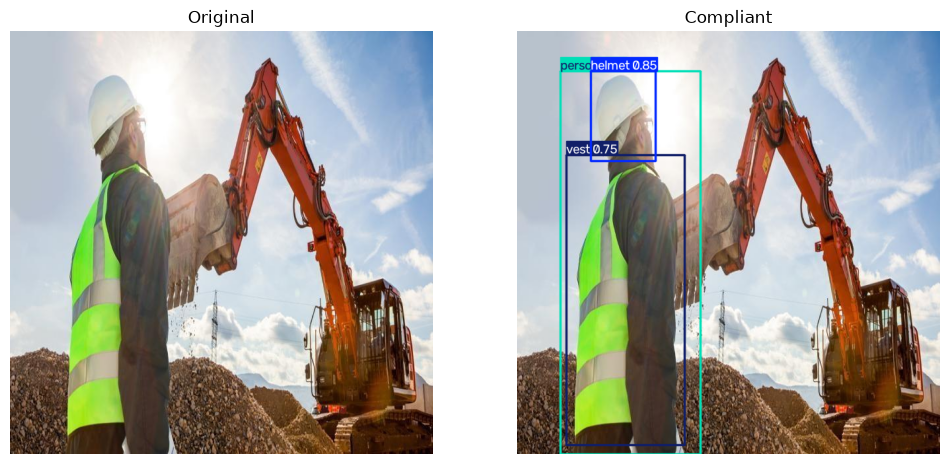

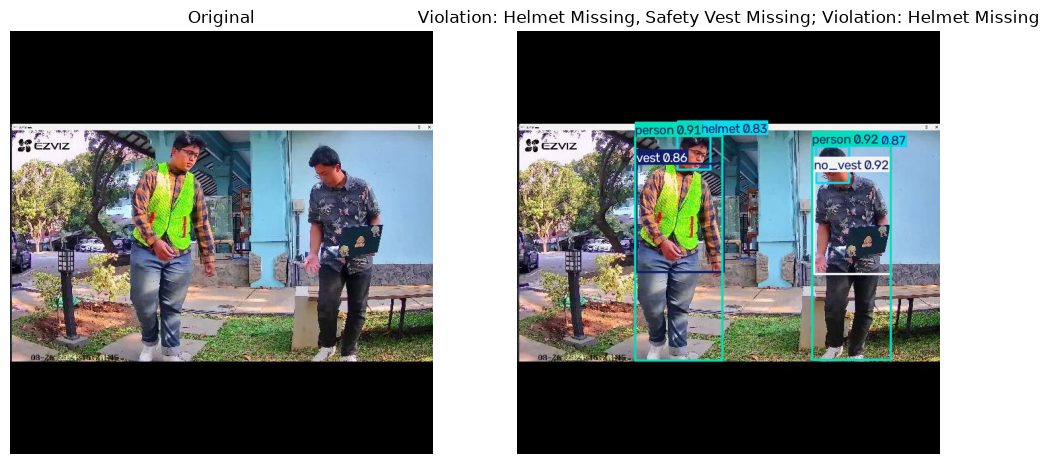

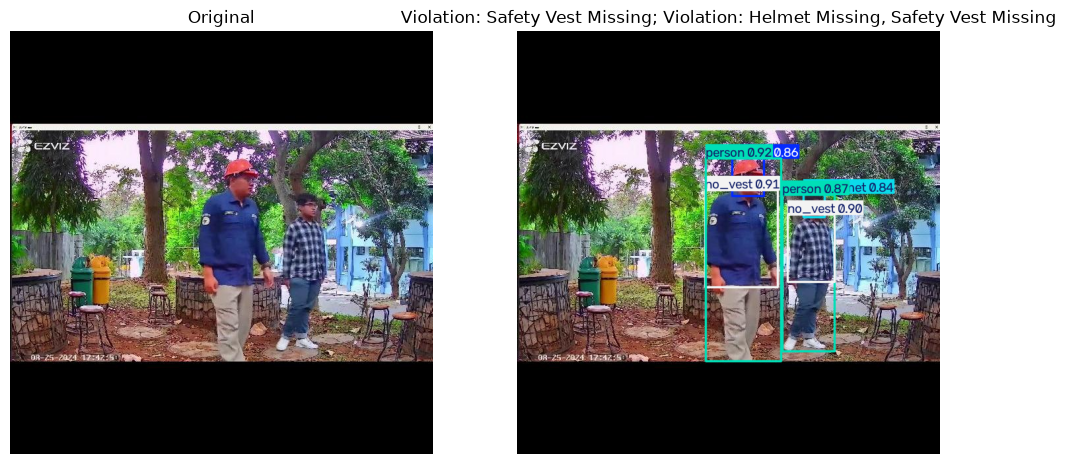

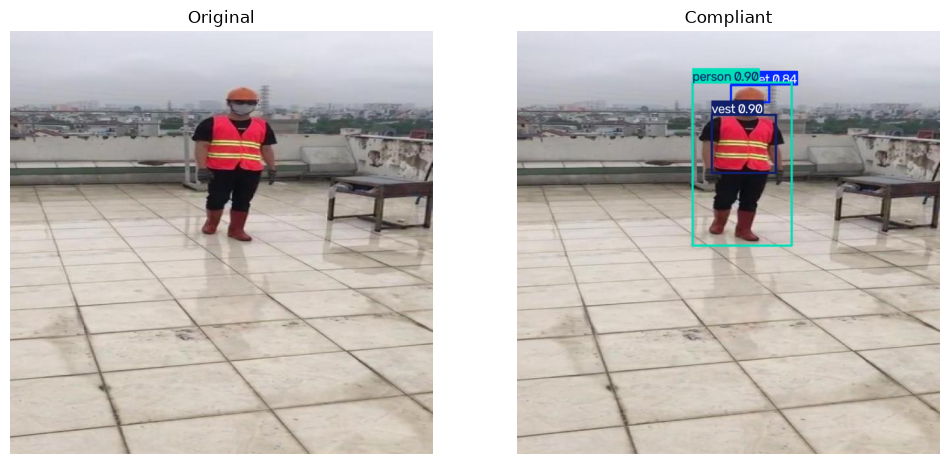

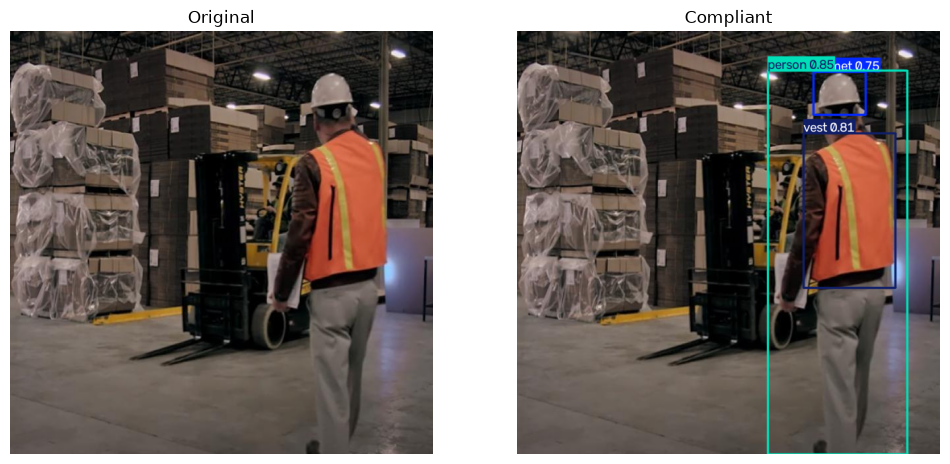

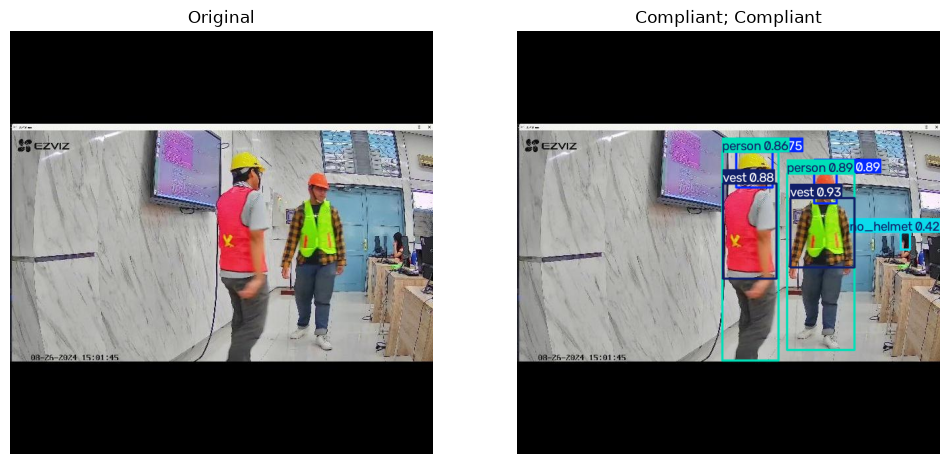

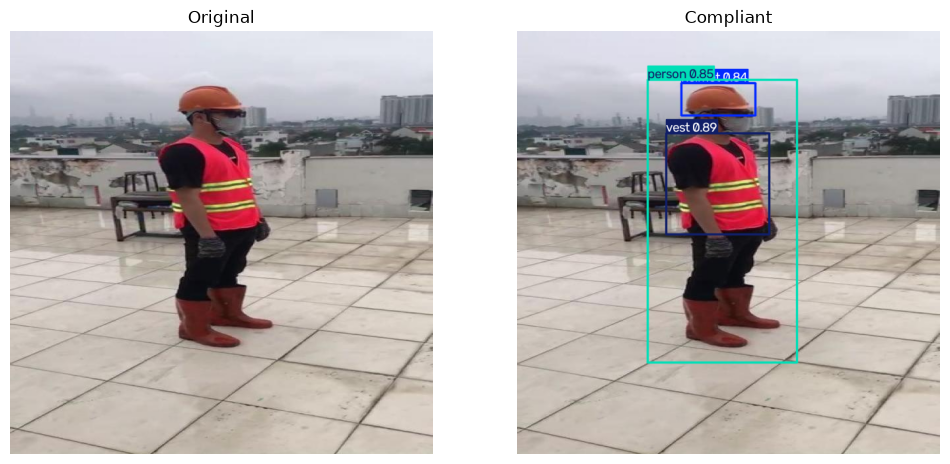

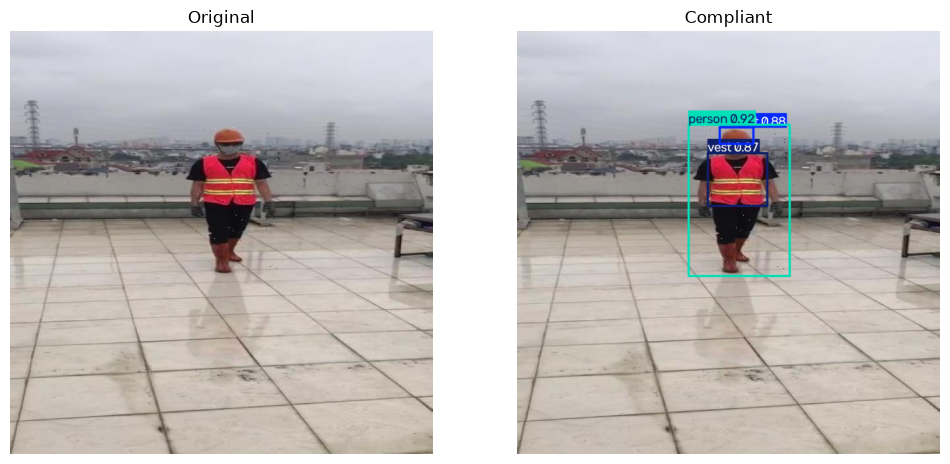

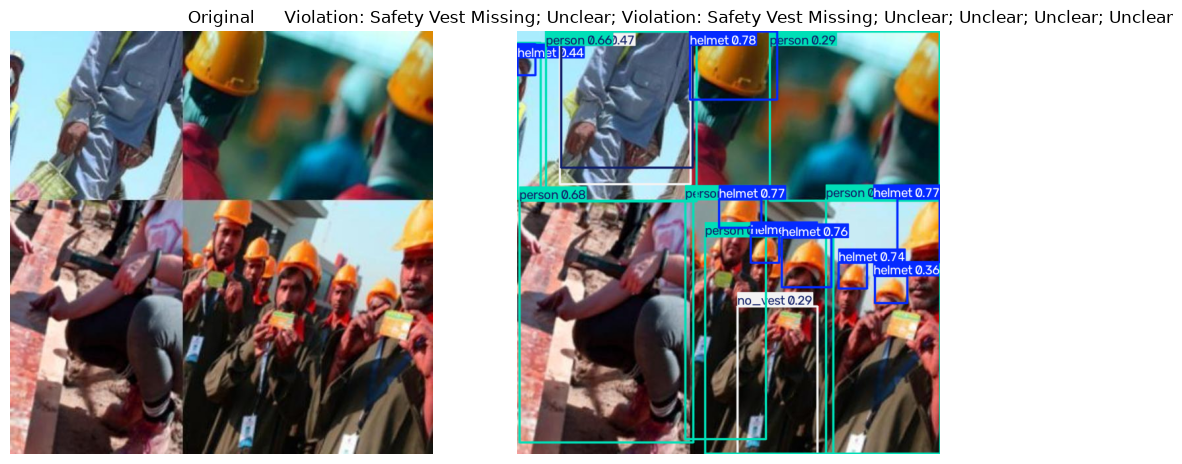

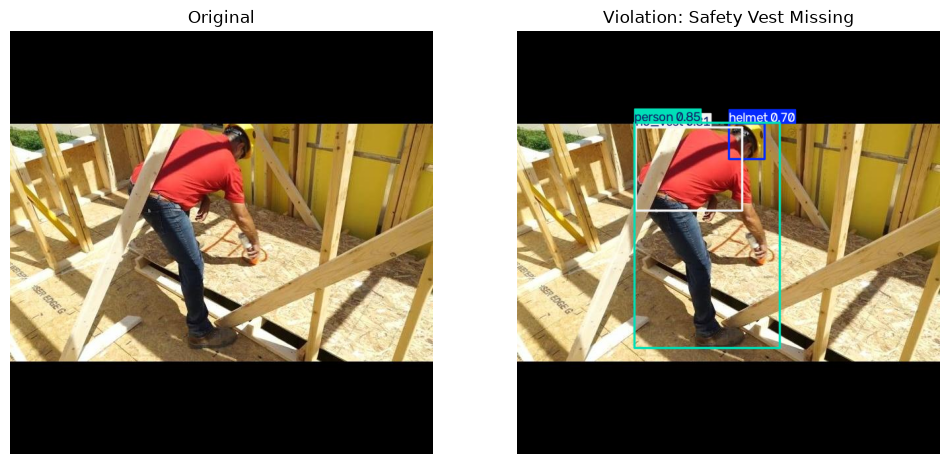

In [17]:
# 10 unseen test images
test_imgs = random.sample(list((root / "test" / "images").glob("*.*")), 10)
all_status = []

for p in test_imgs:
    r = best.predict(p, conf=0.25, device=0, verbose=False)[0]
    status = check_workers(r)
    all_status += status

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); ax[0].set_title("Original")
    ax[1].imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax[1].set_title("; ".join(status) or "No worker")
    for a in ax: a.axis("off")
    plt.show()



In [18]:
# dashboard metrics
total = len(all_status)
compliant = sum(s == "Compliant" for s in all_status)
print("Total workers      :", total)
print("Compliant          :", compliant)
print("Non-compliant      :", total - compliant)
print("Compliance %       :", round(100 * compliant / max(total, 1), 1))
print("Helmet violations  :", sum("Helmet" in s for s in all_status))
print("Vest violations    :", sum("Vest" in s for s in all_status))

Total workers      : 19
Compliant          : 7
Non-compliant      : 12
Compliance %       : 36.8
Helmet violations  : 3
Vest violations    : 6
